# 06 — Our contributions (round 4): decision layer, out-of-fold distillation, and the SOTA question

**Goal.** Add our own contribution on top of the round-3 ensemble and compare against the best published results on the
official ISIC 2018 Task 3 test set (balanced multiclass accuracy):

| Entry | Bal. acc. | Data |
|---|---|---|
| Gessert et al. 2018 (2nd place) | 0.856 | HAM10000, 54-model ensemble |
| MetaOptima 2018 (challenge winner) | 0.885 | external data |
| Sun et al. 2021, live leaderboard, ensemble of 2 EfficientNets | **0.895** | ISIC 2019 + 4 other datasets + patient metadata |
| Ours, round 3 (25 models) | 0.892 | HAM10000 only |

**Three questions** (plan fixed before seeing round-4 results: `research/round4_plan.md`):
1. **Decision layer.** Round 3 showed better ranking (AUC) without better balanced accuracy. Can a decision layer fitted on
   **out-of-fold (OOF)** predictions fix this? Selection by **nested CV** (fit on 4 folds' OOF, score the 5th).
2. **Out-of-fold ensemble distillation (main contribution).** Train single students on the calibrated OOF probabilities of
   the 5-backbone ensemble (`make_soft_labels.py`; loss = 0.5·CE(hard) + 0.5·CE(soft)). Settings fixed in advance.
   *Caveat:* a student's soft labels come from fold models trained on its own CV fold, so student CV is optimistic;
   students are judged on the **test set**, against hard-label twins, with no variant selection.
3. **FixRes.** Evaluate the CNN checkpoints at 512 px instead of 448 px; adopt only if a member's own CV improves.

In [1]:
import json
import subprocess
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

HWX_DIR = Path.cwd() if (Path.cwd() / "isic").is_dir() else Path.cwd().parent
sys.path.insert(0, str(HWX_DIR))
from isic import analysis as A
from isic.data import CLASSES

pd.set_option("display.width", 200)
RUN_TRAINING = False   # True on a GPU node: re-create one distilled student fold (~27 min) before the analysis

def run(cmd):
    print("$", cmd, flush=True)
    subprocess.run(cmd, shell=True, check=True, cwd=HWX_DIR)

BB = ["resnet50_ce_res448_tta20", "convnext_s_res448_tta20", "effv2_s_res448_tta20", "dinov2_b14_res448_tta20", "vit_b16_res448_tta20"]
KD = ["resnet50_kd_res448_tta20", "effv2_s_kd_res448_tta20", "convnext_s_kd_res448_tta20"]

In [2]:
if RUN_TRAINING:
    run("python make_soft_labels.py --members " + " ".join(BB) + " --out results/soft_labels/bb5_calib_oof.csv")
    run("python train_classifier.py --run-name convnext_s_kd_res448 --model convnext_small.fb_in22k_ft_in1k --lr 2e-4 "
        "--img-size 448 --soft-labels results/soft_labels/bb5_calib_oof.csv --kd-alpha 0.5 --fold 0")
    run("python evaluate_tta.py convnext_s_kd_res448 --crops 5 --folds 0")
    run("python posthoc_logit_adjustment.py convnext_s_kd_res448_tta20")

## 1. Decision layers on out-of-fold predictions (nested CV)

In [3]:
dl = json.loads((A.RESULTS / "comparisons" / "decision_layer_bb5.json").read_text())
t = pd.DataFrame(dl["rows"]).set_index("method")[["description", "cv_nested", "cv_std", "test_per_fold", "test_all_models"]]
t.round(4)

,description,cv_nested,cv_std,test_per_fold,test_all_models
method,,,,,
member_tau,"per-member tau, then average probabilities (ro...",0.8719,0.0102,0.8732,0.8861
avg_tau,"average log-probs, single tau",0.8744,0.0161,0.8780,0.8893
avg_bias,"average log-probs, per-class bias",0.8714,0.0060,0.8681,0.8851
calib_tau1,"temperature-calibrate members, average, tau = ...",0.8706,0.0149,0.8799,0.8966
calib_tau,"temperature-calibrate members, average, single...",0.8746,0.0156,0.8791,0.8895
calib_bias,"temperature-calibrate members, average, per-cl...",0.8707,0.0099,0.8651,0.8918
stack,class-balanced logistic-regression stacker on ...,0.8522,0.0150,0.8303,0.8813


All variants sit within ±0.004 on nested CV (fold std ≈ 0.015): the decision layer is not the bottleneck. More flexible
layers overfit (per-class biases −0.003, logistic-regression stacker −0.022). Selected: **calib_tau** (temperature-calibrate
each member, average log-probs, one τ) — best nested CV and the most stable per-fold test score. The zero-parameter
`calib_tau1` happens to reach 0.897 on test but is not the CV winner, so it is not used.

## 2. Out-of-fold ensemble distillation: students vs hard-label twins

In [4]:
sl = pd.read_csv(A.RESULTS / "soft_labels" / "bb5_calib_oof.csv")
y = sl["label"].map(CLASSES.index).to_numpy(); P = sl[CLASSES].to_numpy()
print(f"soft labels: {len(sl)} images | mean prob on true class {P[np.arange(len(y)), y].mean():.3f} | "
      f"mean entropy {(-(P * np.log(P + 1e-9)).sum(1)).mean():.3f} nats")
print("mean soft-label mass per true class (rows) -> class (cols): what the teacher thinks each class resembles")
pd.DataFrame([P[y == c].mean(0) for c in range(7)], index=CLASSES, columns=CLASSES).round(3)

soft labels: 10015 images | mean prob on true class 0.859 | mean entropy 0.301 nats
mean soft-label mass per true class (rows) -> class (cols): what the teacher thinks each class resembles


,MEL,NV,BCC,AKIEC,BKL,DF,VASC
MEL,0.629,0.257,0.016,0.016,0.068,0.007,0.007
NV,0.036,0.936,0.006,0.004,0.013,0.003,0.003
BCC,0.022,0.046,0.838,0.046,0.028,0.011,0.008
AKIEC,0.048,0.051,0.094,0.666,0.121,0.018,0.003
BKL,0.096,0.106,0.025,0.042,0.719,0.008,0.003
DF,0.091,0.126,0.071,0.077,0.059,0.566,0.009
VASC,0.030,0.062,0.028,0.003,0.007,0.007,0.862


In [5]:
pairs = [("ResNet-50", "resnet50_ce_res448_tta20_la", "resnet50_kd_res448_tta20_la"),
         ("EfficientNetV2-S", "effv2_s_res448_tta20_la", "effv2_s_kd_res448_tta20_la"),
         ("ConvNeXt-S", "convnext_s_res448_tta20_la", "convnext_s_kd_res448_tta20_la")]
rows = []
for name, hard, kd in pairs:
    for tag, r in (("hard labels", hard), ("distilled", kd)):
        te = A.per_fold(r)
        rows.append({"model": f"{name} · {tag}", "test_bal_acc": te.bal_acc.mean(), "std": te.bal_acc.std(ddof=0),
                     "test_auc": te.auc.mean(), "test_f1": te.f1.mean(), "test_mel_sens": te.mel_sens.mean(),
                     "cv_bal_acc (optimistic for students)": A.per_fold(r, "cv_val").bal_acc.mean()})
display(pd.DataFrame(rows).set_index("model").round(4))
pd.concat([A.paired_table([kd], hard, names=[f"{n}: distilled - hard"], splits=("official_test",),
                          metrics=("balanced_acc", "macro_auc", "mel_sensitivity", "macro_f1")) for n, hard, kd in pairs])

,test_bal_acc,std,test_auc,test_f1,test_mel_sens,cv_bal_acc (optimistic for students)
model,,,,,,
ResNet-50 · hard labels,0.8346,0.0135,0.9727,0.7205,0.7591,0.8313
ResNet-50 · distilled,0.8543,0.0083,0.9792,0.7503,0.7942,0.8782
EfficientNetV2-S · hard labels,0.8324,0.0122,0.9776,0.7703,0.7439,0.8371
EfficientNetV2-S · distilled,0.8508,0.0077,0.9812,0.7798,0.7895,0.8690
ConvNeXt-S · hard labels,0.8170,0.0174,0.9766,0.7613,0.7474,0.8427
ConvNeXt-S · distilled,0.8639,0.0095,0.9826,0.7985,0.7953,0.8880


,test_bal_acc,test_auc,test_mel_sens,test_f1
ResNet-50: distilled - hard,+0.020 ± 0.011 (5/5),+0.006 ± 0.003 (5/5),+0.035 ± 0.031 (5/5),+0.030 ± 0.032 (4/5)
EfficientNetV2-S: distilled - hard,+0.018 ± 0.005 (5/5),+0.004 ± 0.001 (5/5),+0.046 ± 0.044 (4/5),+0.010 ± 0.008 (4/5)
ConvNeXt-S: distilled - hard,+0.047 ± 0.020 (5/5),+0.006 ± 0.002 (5/5),+0.048 ± 0.035 (5/5),+0.037 ± 0.033 (4/5)


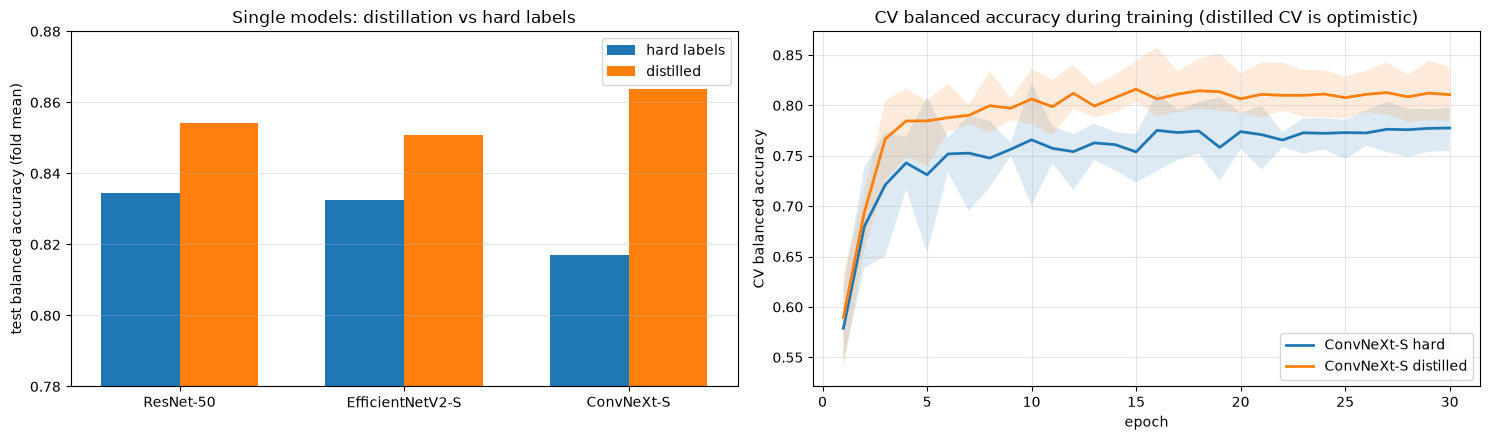

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
x = np.arange(len(pairs)); w = 0.35
hard = [A.per_fold(h).bal_acc.mean() for _, h, _ in pairs]; kd = [A.per_fold(k).bal_acc.mean() for _, _, k in pairs]
axes[0].bar(x - w / 2, hard, w, label="hard labels"); axes[0].bar(x + w / 2, kd, w, label="distilled")
axes[0].set_xticks(x, [p[0] for p in pairs]); axes[0].set_ylim(0.78, 0.88); axes[0].set_ylabel("test balanced accuracy (fold mean)")
axes[0].grid(axis="y", alpha=.3); axes[0].legend(); axes[0].set_title("Single models: distillation vs hard labels")
A.plot_curves(axes[1], ["convnext_s_res448", "convnext_s_kd_res448"], ["ConvNeXt-S hard", "ConvNeXt-S distilled"])
axes[1].set_title("CV balanced accuracy during training (distilled CV is optimistic)")
plt.tight_layout()

## 3. FixRes (test at 512 px) — decided on each member's own CV

In [7]:
rows = []
for r in ["resnet50_ce_res448", "convnext_s_res448", "effv2_s_res448"]:
    a, b = f"{r}_tta20_la", f"{r}_tta20_ts512_la"
    mu, sd, better, n = A.paired(b, a, "cv_val"); tmu, _, tb, _ = A.paired(b, a, "official_test")
    rows.append({"member": r, "cv 448": A.per_fold(a, "cv_val").bal_acc.mean(), "cv 512": A.per_fold(b, "cv_val").bal_acc.mean(),
                 "cv paired": f"{mu:+.4f} ({better}/5)", "decision": "use 512" if mu > 0 else "keep 448",
                 "test paired (reporting only)": f"{tmu:+.4f} ({tb}/5)"})
pd.DataFrame(rows).set_index("member").round(4)

,cv 448,cv 512,cv paired,decision,test paired (reporting only)
member,,,,,
resnet50_ce_res448,0.8313,0.8200,-0.0113 (1/5),keep 448,+0.0049 (4/5)
convnext_s_res448,0.8427,0.8370,-0.0057 (1/5),keep 448,+0.0018 (3/5)
effv2_s_res448,0.8371,0.8382,+0.0011 (4/5),use 512,-0.0090 (1/5)


## 4. The pre-registered final model and the SOTA question

In [8]:
cands = {"5 backbones (round 3, per-member tau)": "ens5_res448_tta20_la",
         "5 backbones + FixRes rule (calib_tau)": "dl_bb5fx_calib_tau",
         "3 distilled students (calib_tau)": "dl_kd3_calib_tau",
         "FINAL: 5 backbones + 3 students (calib_tau, pre-registered)": "dl_final8_calib_tau"}
display(A.summary(list(cands.values()), names=list(cands)))

def allmodels(run):
    ps = [pd.read_csv(A.RESULTS / run / f"fold{k}" / "pred_official_test.csv") for k in range(5)]
    return ps[0]["label"].map(CLASSES.index).to_numpy(), np.mean([p[CLASSES].to_numpy() for p in ps], 0).argmax(1)
def bacc(y, p): return np.mean([(p[y == c] == c).mean() for c in range(7)])
rng = np.random.default_rng(0); y0, _ = allmodels("dl_final8_calib_tau")
B = [np.concatenate([rng.choice(np.where(y0 == c)[0], (y0 == c).sum()) for c in range(7)]) for _ in range(2000)]
rows = []
for name, r in cands.items():
    _, p = allmodels(r); bs = np.array([bacc(y0[b], p[b]) for b in B])
    rows.append({"model (all fold models averaged)": name, "test bal. acc.": bacc(y0, p),
                 "95% CI low": np.percentile(bs, 2.5), "95% CI high": np.percentile(bs, 97.5), "P(> 0.895)": (bs > 0.895).mean()})
pd.DataFrame(rows).set_index("model (all fold models averaged)").round(3)

,bal_acc,acc,f1,auc,mel_sens,mel_spec,ensemble_bal_acc,n_folds
"5 backbones (round 3, per-member tau)",0.877 ± 0.014,0.873 ± 0.013,0.818 ± 0.022,0.984 ± 0.001,0.811 ± 0.025,0.939 ± 0.002,0.892,5
5 backbones + FixRes rule (calib_tau),0.877 ± 0.006,0.877 ± 0.010,0.822 ± 0.018,0.986 ± 0.001,0.812 ± 0.012,0.942 ± 0.002,0.892,5
3 distilled students (calib_tau),0.873 ± 0.007,0.861 ± 0.005,0.797 ± 0.010,0.985 ± 0.000,0.820 ± 0.018,0.933 ± 0.005,0.882,5
"FINAL: 5 backbones + 3 students (calib_tau, pre-registered)",0.883 ± 0.008,0.879 ± 0.004,0.826 ± 0.008,0.987 ± 0.000,0.811 ± 0.019,0.942 ± 0.002,0.888,5


,test bal. acc.,95% CI low,95% CI high,P(> 0.895)
model (all fold models averaged),,,,
"5 backbones (round 3, per-member tau)",0.892,0.868,0.916,0.424
5 backbones + FixRes rule (calib_tau),0.892,0.867,0.915,0.404
3 distilled students (calib_tau),0.882,0.856,0.907,0.146
"FINAL: 5 backbones + 3 students (calib_tau, pre-registered)",0.888,0.862,0.913,0.290


## Takeaways
* **Out-of-fold ensemble distillation is our clearest contribution.** With identical recipes, distilled students beat their
  hard-label twins on the untouched test set on every fold: ConvNeXt-S 0.817 → **0.864** (+0.047), ResNet-50 +0.020,
  EfficientNetV2-S +0.018, with higher AUC (+0.004 to +0.006) and melanoma sensitivity (+0.035 to +0.048). Unlike loss
  weighting, this improves the features, not just the decision threshold. The best single model is now 0.864 (was 0.835).
* **The decision layer is not the bottleneck.** Nested CV puts all OOF decision layers within ±0.004; flexible ones overfit.
* **FixRes does not help** here (adopted only for EfficientNetV2-S by the pre-set rule, +0.001 CV).
* **SOTA:** the pre-registered final model (8 backbones/students, 40 networks) reaches **0.888** (per-fold 0.883 ± 0.008, our
  most stable result); the 5-backbone ensemble 0.892. The test set's 95% interval is about ±0.025, so these **match** the best
  published result (0.895, which used external data and patient metadata) using HAM10000 alone — but they do not
  measurably beat it, and on this test set no method within ~0.02 of it can be shown to.
* Adding distilled students to the ensemble does not help (−0.004, CI [−0.012, +0.003]): they inherit the ensemble's
  knowledge rather than adding diversity.